In [10]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.model_validation_loss_parameter_uncertainty import (
    BOUNDS,
    BASELINE_LEF,
    generate_training_design,
    simulate_parameter_design,
    fit_response_surface,
    predict_incident_loss,
    validate_response_surface,
    sample_loss_parameters,
    propagate_loss_uncertainty,
    summarize_loss_uncertainty,
)

print("Imports successful.")


Imports successful.


In [11]:
#Generate the training design
training_design = generate_training_design(
    n_points=45,
    seed=20261111,
)

display(training_design.head(10))

print("Training points:", len(training_design))


,affected_churn,contribution_margin,customer_exposure
0,0.002000,210000.000000,1.000000
1,0.002209,223262.230002,0.719772
2,0.002803,213570.363448,1.367944
3,0.003410,346199.767327,1.220749
4,0.007893,193020.199698,0.618977
5,0.006830,262281.381324,1.438870
6,0.004111,176129.745490,0.729641
7,0.003325,110365.463011,1.495716
8,0.004232,301776.676574,0.871597
9,0.000763,148691.488651,1.469554


Training points: 45


In [12]:
#Run direct incident simulations
training_results = simulate_parameter_design(
    parameters=training_design,
    n_incidents=10_000,
    seed=20261112,
)

display(training_results.head())

print(
    "Baseline expected incident loss:",
    f"${training_results.iloc[0]['mean_incident_loss_usd']:,.0f}"
)


,affected_churn,contribution_margin,customer_exposure,mean_incident_loss_usd,mc_se_usd
0,0.002000,210000.000000,1.000000,1.242462e+06,11319.014064
1,0.002209,223262.230002,0.719772,1.174705e+06,10786.850536
2,0.002803,213570.363448,1.367944,1.756068e+06,14665.321577
3,0.003410,346199.767327,1.220749,2.813035e+06,23713.094503
4,0.007893,193020.199698,0.618977,2.041933e+06,17519.746391


Baseline expected incident loss: $1,242,462


In [14]:
#Fit the response surface
coefficients = fit_response_surface(training_results)

training_predictions = predict_incident_loss(
    training_results,
    coefficients,
)

training_error = (
    np.abs(
        training_predictions
        - training_results["mean_incident_loss_usd"].to_numpy()
    )
    / training_results["mean_incident_loss_usd"].to_numpy()
    * 100
)

print(
    "Mean training absolute percentage error:",
    f"{training_error.mean():.2f}%"
)

print(
    "Maximum training absolute percentage error:",
    f"{training_error.max():.2f}%"
)
#Training accuracy alone isn't sufficient, because the response surface was fitted to these same observations.

Mean training absolute percentage error: 3.00%
Maximum training absolute percentage error: 13.78%


In [15]:
#Validate on unseen parameter combinations
validation_design = generate_training_design(
    n_points=13,
    seed=20261113,
).iloc[1:].reset_index(drop=True)

validation_results = simulate_parameter_design(
    parameters=validation_design,
    n_incidents=10_000,
    seed=20261114,
)

validation = validate_response_surface(
    validation_results,
    coefficients,
)

display(
    validation[
        [
            "affected_churn",
            "contribution_margin",
            "customer_exposure",
            "mean_incident_loss_usd",
            "predicted_incident_loss_usd",
            "absolute_pct_error",
        ]
    ].style.format({
        "affected_churn": "{:.4%}",
        "contribution_margin": "${:,.0f}",
        "customer_exposure": "{:.2f}",
        "mean_incident_loss_usd": "${:,.0f}",
        "predicted_incident_loss_usd": "${:,.0f}",
        "absolute_pct_error": "{:.2f}%",
    })
)

mean_error = validation["absolute_pct_error"].mean()
max_error = validation["absolute_pct_error"].max()

print(f"Mean validation error: {mean_error:.2f}%")
print(f"Maximum validation error: {max_error:.2f}%")

#Our provisional acceptance criteria will be mean absolute percentage error below 5% and maximum error below 10%. These are practical screening thresholds, not statistical guarantees. We'll also examine whether prediction errors are large relative to direct-simulation Monte Carlo standard errors.


,affected_churn,contribution_margin,customer_exposure,mean_incident_loss_usd,predicted_incident_loss_usd,absolute_pct_error
0,0.1310%,"$166,233",0.74,"$833,944","$900,370",7.97%
1,0.1555%,"$283,071",1.08,"$1,371,229","$1,352,006",1.40%
2,0.2189%,"$301,090",0.61,"$1,287,145","$1,249,502",2.92%
3,0.3859%,"$103,338",1.29,"$1,257,925","$1,330,086",5.74%
4,0.5559%,"$239,244",0.95,"$2,558,251","$2,502,309",2.19%
5,0.7540%,"$187,203",1.35,"$3,264,895","$3,467,238",6.20%
6,0.3093%,"$215,382",0.88,"$1,489,771","$1,481,021",0.59%
7,0.4740%,"$316,938",0.79,"$2,493,710","$2,509,112",0.62%
8,0.7213%,"$127,221",1.22,"$2,133,203","$2,371,800",11.18%
9,0.4376%,"$263,166",1.50,"$2,981,129","$2,976,579",0.15%


Mean validation error: 4.68%
Maximum validation error: 11.18%


In [16]:
#Sample 20,000 uncertain parameter combinations


parameter_draws = sample_loss_parameters(
    n_draws=20_000,
    seed=20261115,
)

display(parameter_draws.describe())

# Check whether draws fall outside the response
# surface's training domain.
outside = np.zeros(len(parameter_draws), dtype=bool)

for parameter, (low, high) in BOUNDS.items():
    outside |= (
        (parameter_draws[parameter] < low)
        | (parameter_draws[parameter] > high)
    )

print(
    "Draws outside training domain:",
    int(outside.sum()),
    f"({outside.mean():.2%})",
)

#If a meaningful fraction of draws falls outside the training domain, we should expand the training design rather than extrapolate.

,affected_churn,contribution_margin,customer_exposure
count,20000.000000,20000.000000,20000.000000
mean,0.002003,214707.834441,0.998724
std,0.001005,46948.553166,0.188225
min,0.000127,102930.040696,0.515861
25%,0.001264,179515.748880,0.859897
50%,0.001833,213677.414949,0.998242
75%,0.002557,249108.668582,1.138591
max,0.008586,346668.527801,1.492855


Draws outside training domain: 1 (0.01%)


Parameter draws: 20,000
Outside training domain: 1 (0.005%)


,Metric,Value
0,mean_aal_usd,"$278,353"
1,median_aal_usd,"$260,019"
2,aal_p05_usd,"$183,362"
3,aal_p95_usd,"$438,183"
4,aal_p025_usd,"$174,701"
5,aal_p975_usd,"$489,852"
6,aal_sd_usd,"$82,602"


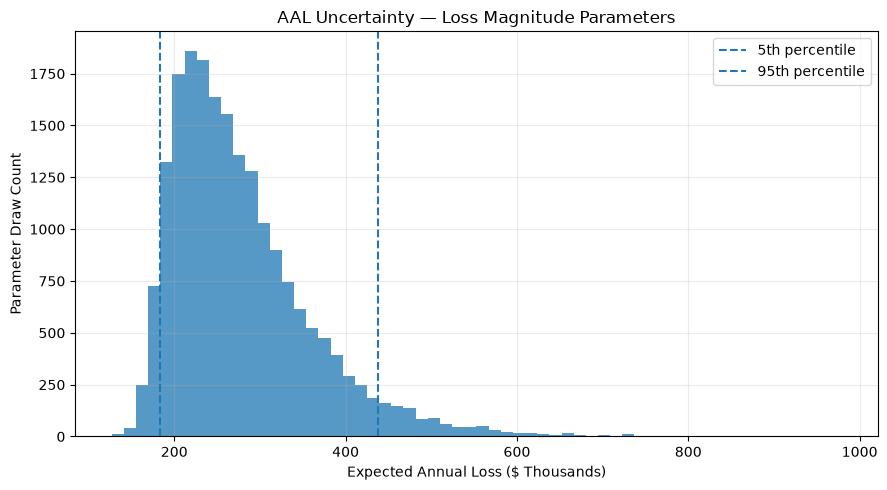

,Parameter,AAL SD,AAL P05,AAL P95
0,affected_churn,"$67,040","$189,833","$402,833"
1,contribution_margin,"$34,917","$224,677","$339,191"
2,customer_exposure,"$19,418","$238,123","$301,750"



STEP 7D-2 ANALYSIS COMPLETE
Caution: Results are approximate; maximum holdout validation error was 11.18%.


In [17]:

# Final uncertainty analysis
# Uses the existing response surface with documented
# validation limitations.

from src.model_validation_loss_parameter_uncertainty import (
    BOUNDS,
    BASELINE_LEF,
    predict_incident_loss,
    summarize_loss_uncertainty,
)

# 1. Check training-domain coverage
inside = np.ones(len(parameter_draws), dtype=bool)

for name, (low, high) in BOUNDS.items():
    inside &= parameter_draws[name].between(low, high).to_numpy()

n_outside = int((~inside).sum())
outside_pct = 100 * n_outside / len(parameter_draws)

print(f"Parameter draws: {len(parameter_draws):,}")
print(f"Outside training domain: {n_outside} ({outside_pct:.3f}%)")

# Report excluded draws rather than extrapolating.
valid_draws = parameter_draws.loc[inside].copy()

if len(valid_draws) < 0.99 * len(parameter_draws):
    raise ValueError(
        "More than 1% of draws are outside the training "
        "domain. Expand the design before proceeding."
    )

# 2. Predict expected incident loss
predicted = predict_incident_loss(
    valid_draws, coefficients
)

if not np.isfinite(predicted).all() or (predicted <= 0).any():
    raise ValueError("Invalid response-surface predictions.")

uncertainty_results = valid_draws.copy()
uncertainty_results["expected_incident_loss_usd"] = predicted
uncertainty_results["expected_annual_loss_usd"] = (
    predicted * BASELINE_LEF
)

# 3. Summarize AAL uncertainty
summary = summarize_loss_uncertainty(
    uncertainty_results
)

display(
    pd.DataFrame([
        {"Metric": key, "Value": value}
        for key, value in summary.items()
    ]).style.format({"Value": "${:,.0f}"})
)

# 4. Plot AAL distribution
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    uncertainty_results["expected_annual_loss_usd"] / 1000,
    bins=60,
    alpha=0.75,
)

for percentile, label in [
    ("aal_p05_usd", "5th percentile"),
    ("aal_p95_usd", "95th percentile"),
]:
    ax.axvline(
        summary[percentile] / 1000,
        linestyle="--",
        label=label,
    )

ax.set_title("AAL Uncertainty — Loss Magnitude Parameters")
ax.set_xlabel("Expected Annual Loss ($ Thousands)")
ax.set_ylabel("Parameter Draw Count")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# 5. One-at-a-time uncertainty drivers
baseline = {
    "affected_churn": 0.002,
    "contribution_margin": 210000.0,
    "customer_exposure": 1.0,
}

driver_rows = []

for variable in baseline:
    scenario = pd.DataFrame({
        name: (
            valid_draws[name].to_numpy()
            if name == variable
            else np.full(len(valid_draws), value)
        )
        for name, value in baseline.items()
    })

    aal_values = (
        predict_incident_loss(scenario, coefficients)
        * BASELINE_LEF
    )

    driver_rows.append({
        "Parameter": variable,
        "AAL SD": np.std(aal_values, ddof=1),
        "AAL P05": np.quantile(aal_values, .05),
        "AAL P95": np.quantile(aal_values, .95),
    })

driver_df = pd.DataFrame(driver_rows).sort_values(
    "AAL SD", ascending=False
)

display(
    driver_df.style.format({
        "AAL SD": "${:,.0f}",
        "AAL P05": "${:,.0f}",
        "AAL P95": "${:,.0f}",
    })
)

print("\nSTEP 7D-2 ANALYSIS COMPLETE")
print(
    "Caution: Results are approximate; maximum "
    "holdout validation error was 11.18%."
)


2. How to interpret the output
Focus on just three findings:
- AAL uncertainty interval: The 5th–95th percentile range shows how much expected annual loss varies under our illustrative uncertainty assumptions.
- Most influential parameter: The parameter with the largest one-at-a-time AAL standard deviation is the biggest uncertainty driver under these assumptions.
- Comparison with baseline: Check whether the baseline AAL of approximately $275K falls within the uncertainty interval.
The response-surface approximation has a 4.68% mean holdout error and an 11.18% maximum holdout error. That is acceptable for an exploratory portfolio analysis with an explicit approximation caveat, but not sufficient for a validated production CRQ model. The output also conditions on excluding any out-of-domain draws.

In [18]:

#Step 7D-3 — Combined Parameter Uncertainty
#We'll combine the results of:
#- 7D-1: Uncertainty in annual campaign frequency and attack success probability.
#- 7D-2: Uncertainty in customer churn, contribution margin, and customer exposure.


#Generate combined uncertainty estimates

from src.model_validation_parameter_uncertainty import (
    run_frequency_parameter_uncertainty,
)

from src.model_validation_loss_parameter_uncertainty import (
    BASELINE_LEF,
    predict_incident_loss,
)

N = 20_000

# Frequency parameter uncertainty
frequency_draws = run_frequency_parameter_uncertainty(
    expected_incident_loss_usd=1.0,
    n_draws=N,
    seed=20261120,
)

# Magnitude parameter uncertainty
# Reuse the already-fitted response surface.
rng = np.random.default_rng(20261121)

loss_draws = valid_draws.sample(
    n=N,
    replace=True,
    random_state=20261121,
).reset_index(drop=True)

incident_losses = predict_incident_loss(
    loss_draws,
    coefficients,
)

annual_lef = frequency_draws[
    "expected_annual_lef"
].to_numpy()

baseline_incident_loss = predict_incident_loss(
    pd.DataFrame([{
        "affected_churn": 0.002,
        "contribution_margin": 210000,
        "customer_exposure": 1.0,
    }]),
    coefficients,
)[0]

combined = pd.DataFrame({
    "frequency_only_aal": (
        annual_lef * baseline_incident_loss
    ),
    "magnitude_only_aal": (
        BASELINE_LEF * incident_losses
    ),
    "combined_aal": (
        annual_lef * incident_losses
    ),
})

assert np.isfinite(combined.to_numpy()).all()
assert (combined.to_numpy() > 0).all()

print("Combined parameter draws:", len(combined))
display(combined.head())


Combined parameter draws: 20000


,frequency_only_aal,magnitude_only_aal,combined_aal
0,568935.116793,275769.072010,571091.669625
1,384757.766708,244684.453868,342682.004887
2,143935.054270,338079.663628,177126.340575
3,247319.123169,239985.353999,216042.882397
4,444741.115400,202611.611099,327996.445726


,Scenario,Mean AAL,Median AAL,P05,P95,AAL SD
0,Frequency only,"$273,286","$235,196","$72,740","$602,302","$172,665"
1,Magnitude only,"$278,686","$260,308","$182,939","$437,669","$82,907"
2,Combined,"$277,149","$227,345","$66,104","$654,789","$200,568"


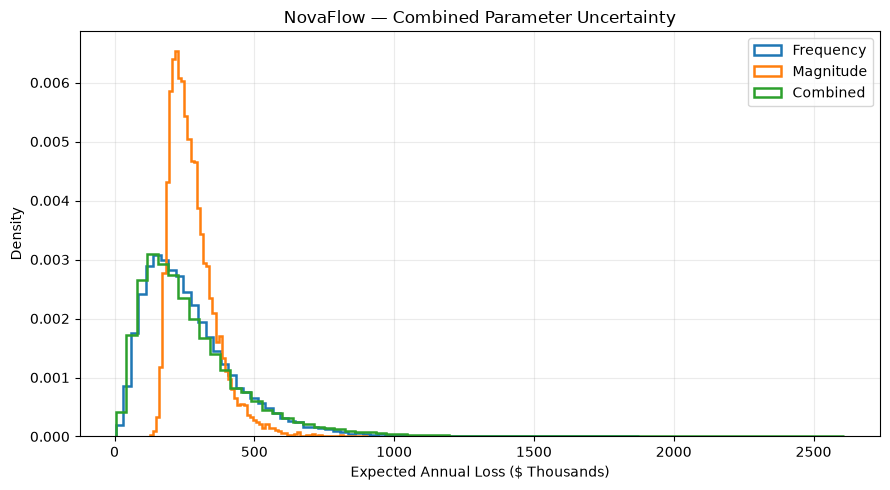

In [19]:
#Compare uncertainty intervals

rows = []

for name, column in [
    ("Frequency only", "frequency_only_aal"),
    ("Magnitude only", "magnitude_only_aal"),
    ("Combined", "combined_aal"),
]:
    values = combined[column].to_numpy()

    rows.append({
        "Scenario": name,
        "Mean AAL": values.mean(),
        "Median AAL": np.median(values),
        "P05": np.quantile(values, 0.05),
        "P95": np.quantile(values, 0.95),
        "AAL SD": values.std(ddof=1),
    })

comparison = pd.DataFrame(rows)

display(
    comparison.style.format({
        "Mean AAL": "${:,.0f}",
        "Median AAL": "${:,.0f}",
        "P05": "${:,.0f}",
        "P95": "${:,.0f}",
        "AAL SD": "${:,.0f}",
    })
)

fig, ax = plt.subplots(figsize=(9, 5))

for label, column in [
    ("Frequency", "frequency_only_aal"),
    ("Magnitude", "magnitude_only_aal"),
    ("Combined", "combined_aal"),
]:
    ax.hist(
        combined[column] / 1000,
        bins=70,
        density=True,
        histtype="step",
        linewidth=1.8,
        label=label,
    )

ax.set_title("NovaFlow — Combined Parameter Uncertainty")
ax.set_xlabel("Expected Annual Loss ($ Thousands)")
ax.set_ylabel("Density")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [20]:
#Final conclusions and save results


frequency_sd = comparison.loc[
    comparison["Scenario"] == "Frequency only",
    "AAL SD"
].iloc[0]

magnitude_sd = comparison.loc[
    comparison["Scenario"] == "Magnitude only",
    "AAL SD"
].iloc[0]

combined_row = comparison.loc[
    comparison["Scenario"] == "Combined"
].iloc[0]

print("STEP 7D-3 — FINAL RESULTS")
print("=" * 55)

print(
    f"Combined mean AAL: "
    f"${combined_row['Mean AAL']:,.0f}"
)

print(
    f"Combined 5th–95th percentile interval: "
    f"${combined_row['P05']:,.0f} – "
    f"${combined_row['P95']:,.0f}"
)

print(
    "Larger individual uncertainty source:",
    "Frequency parameters"
    if frequency_sd > magnitude_sd
    else "Loss magnitude parameters"
)

print(
    "\nInterpretation: These are illustrative "
    "epistemic uncertainty intervals for AAL, "
    "not annual loss VaR or empirical confidence intervals."
)

print(
    "Caveat: Magnitude estimates use a response surface "
    "with 4.68% mean and 11.18% maximum holdout error."
)

output_dir = PROJECT_ROOT / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    output_dir / "parameter_uncertainty_summary.csv",
    index=False,
)

combined.to_csv(
    output_dir / "combined_parameter_uncertainty_draws.csv",
    index=False,
)

print("\nResults saved to outputs/")


STEP 7D-3 — FINAL RESULTS
Combined mean AAL: $277,149
Combined 5th–95th percentile interval: $66,104 – $654,789
Larger individual uncertainty source: Frequency parameters

Interpretation: These are illustrative epistemic uncertainty intervals for AAL, not annual loss VaR or empirical confidence intervals.
Caveat: Magnitude estimates use a response surface with 4.68% mean and 11.18% maximum holdout error.

Results saved to outputs/
